In [16]:
import pandas as pd
import numpy as np
import matplotlib as plt
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.collections import LineCollection
from matplotlib.patches import Rectangle
from matplotlib.animation import FuncAnimation
import seaborn as sns
import sqlite3
import os

# Questions to answer
- How does a player's acceleration in 
- How does a player's CoD in the 3-cone drill translate to cuts during routes?
- How does a player's acceleration differ (possible scaled/adjusted) between the 40-yard dash, 3-cone drill, and shuttle?

In [17]:
con = sqlite3.connect("data/bdb2027.sqlite")
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con))  # list tables
# df = pd.read_sql("SELECT * FROM <table_name>", con)

Empty DataFrame
Columns: [name]
Index: []


In [18]:
combine_results_df = pd.read_csv("data/combine_results.csv")
combine_df = pd.read_csv("data/combine_tracking.csv")
combine_df["time"] = pd.to_datetime(combine_df["time"])
players_df = pd.read_csv("data/players.csv")

In [19]:
def draw_nfl_field(ax, x_min=0, x_max=120, y_max=53.333):
    """Draw a clean top-down NFL field in yards."""
    ax.set_facecolor("#2e6f40")
    # End zones (0-10 and 110-120)
    ax.add_patch(Rectangle((0, 0), 10, y_max, facecolor="#245932", edgecolor="none"))
    ax.add_patch(Rectangle((110, 0), 10, y_max, facecolor="#245932", edgecolor="none"))

    # Yard lines every 5 yards (with major lines every 10)
    for x in range(10, 111, 5):
        lw = 1.5 if x % 10 == 0 else 0.7
        alpha = 0.85 if x % 10 == 0 else 0.45
        ax.axvline(x, color="white", linewidth=lw, alpha=alpha)

    # Sidelines and end lines
    ax.plot([x_min, x_max], [0, 0], color="white", lw=2)
    ax.plot([x_min, x_max], [y_max, y_max], color="white", lw=2)
    ax.plot([0, 0], [0, y_max], color="white", lw=2)
    ax.plot([120, 120], [0, y_max], color="white", lw=2)

    # Yard numbers along top and bottom of playing field
    for yard_line in range(20, 101, 10):
        label = str(yard_line - 10 if yard_line <= 60 else 110 - yard_line)
        ax.text(yard_line, 6, label, color="white", fontsize=9,
                ha="center", va="center", alpha=0.75, fontweight="bold")
        ax.text(yard_line, y_max - 6, label, color="white", fontsize=9,
                ha="center", va="center", alpha=0.75, fontweight="bold", rotation=180)

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(0, y_max)
    ax.set_xlabel("Field Length x (yards)")
    ax.set_ylabel("Field Width y (yards)")
    ax.set_aspect("equal")


def plot_combine_drill(df: pd.DataFrame, player_name: str = "Player", drill_name: str = "Combine Drill"):
    """
    Expected columns in df (sampled every 0.1s):
      - time: datetime64
      - x: float (0 to 120)
      - y: float (0 to 53.33)
      - s: float (instantaneous speed, yds/s)
      - a: float (instantaneous acceleration, yds/s^2)
      - dis: float (distance from previous frame, yds)
      - dir: float (motion direction angle, 0-360 deg)
    """
    df = df.sort_values("time").reset_index(drop=True).copy()
    t0 = df["time"].iloc[0]
    df["elapsed_s"] = (df["time"] - t0).dt.total_seconds()
    df["cum_dist"] = df["dis"].fillna(0).cumsum()

    fig, (ax_field, ax_kin) = plt.subplots(
        2, 1, figsize=(13, 8), gridspec_kw={"height_ratios": [1.35, 1]}, sharex=False
    )

    # --- Panel 1: Field trajectory colored by speed ---
    draw_nfl_field(ax_field)

    points = np.array([df["x"].values, df["y"].values]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)

    norm = plt.Normalize(df["s"].min(), df["s"].max())
    lc = LineCollection(segments, cmap="plasma", norm=norm, linewidth=3.2)
    lc.set_array(df["s"].values[:-1])
    line = ax_field.add_collection(lc)

    cbar = fig.colorbar(line, ax=ax_field, pad=0.015, fraction=0.025)
    cbar.set_label("Speed (yds/s)")

    # Start & end markers
    ax_field.scatter(df["x"].iloc[0], df["y"].iloc[0], color="limegreen", s=70, zorder=5, label="Start")
    ax_field.scatter(df["x"].iloc[-1], df["y"].iloc[-1], color="crimson", s=70, zorder=5, label="End")

    # Direction arrows every 0.5s (5 frames at 10 Hz)
    step = max(1, int(round(0.5 / 0.1)))
    sub = df.iloc[::step]
    # Note: verify angle convention in your dataset (e.g., 0 = +y or 0 = +x, clockwise vs counter-clockwise)
    rad = np.deg2rad(sub["dir"].values)
    dx = np.cos(rad) * 1.4
    dy = np.sin(rad) * 1.4
    ax_field.quiver(
        sub["x"].values, sub["y"].values, dx, dy,
        angles="xy", scale_units="xy", scale=1,
        color="white", edgecolor="black", linewidth=0.5, width=0.0035, zorder=4
    )

    ax_field.set_title(f"{player_name} — {drill_name} Trajectory (Total Dist: {df['cum_dist'].iloc[-1]:.1f} yds)")
    ax_field.legend(loc="upper right")

    # --- Panel 2: Speed & Acceleration over elapsed time ---
    ax_kin.plot(df["elapsed_s"], df["s"], color="#1f77b4", lw=2.2, label="Speed (yds/s)")
    ax_kin.set_ylabel("Speed (yds/s)", color="#1f77b4")
    ax_kin.tick_params(axis="y", labelcolor="#1f77b4")
    ax_kin.grid(True, linestyle="--", alpha=0.4)

    ax_acc = ax_kin.twinx()
    ax_acc.plot(df["elapsed_s"], df["a"], color="#d62728", lw=1.6, alpha=0.85, label="Acceleration (yds/s²)")
    ax_acc.axhline(0, color="gray", lw=0.8, ls=":")
    ax_acc.set_ylabel("Acceleration (yds/s²)", color="#d62728")
    ax_acc.tick_params(axis="y", labelcolor="#d62728")

    ax_kin.set_xlabel("Elapsed Time from Drill Start (seconds)")
    ax_kin.set_title("Speed & Acceleration Profile (10 Hz Tracking)")

    # Combined legend for twin y-axes
    lines_1, labels_1 = ax_kin.get_legend_handles_labels()
    lines_2, labels_2 = ax_acc.get_legend_handles_labels()
    ax_kin.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left")

    plt.tight_layout()
    return fig

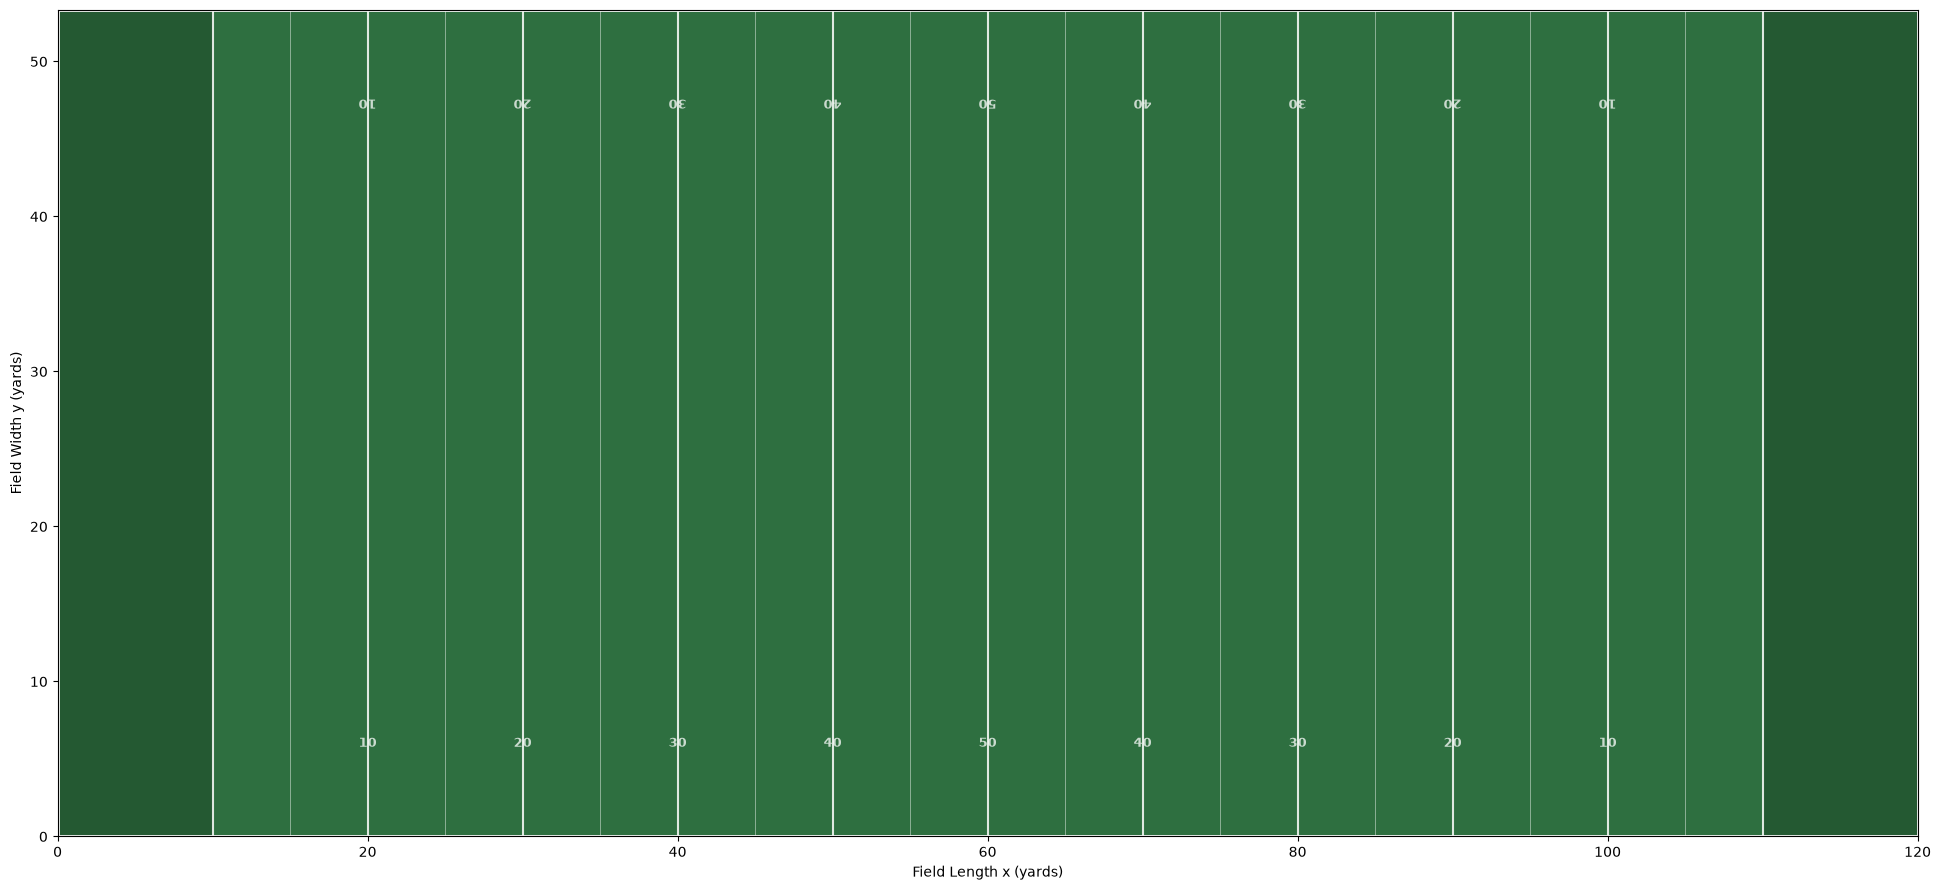

In [20]:
fig,ax = plt.subplots(figsize=(24,11))
draw_nfl_field(ax)

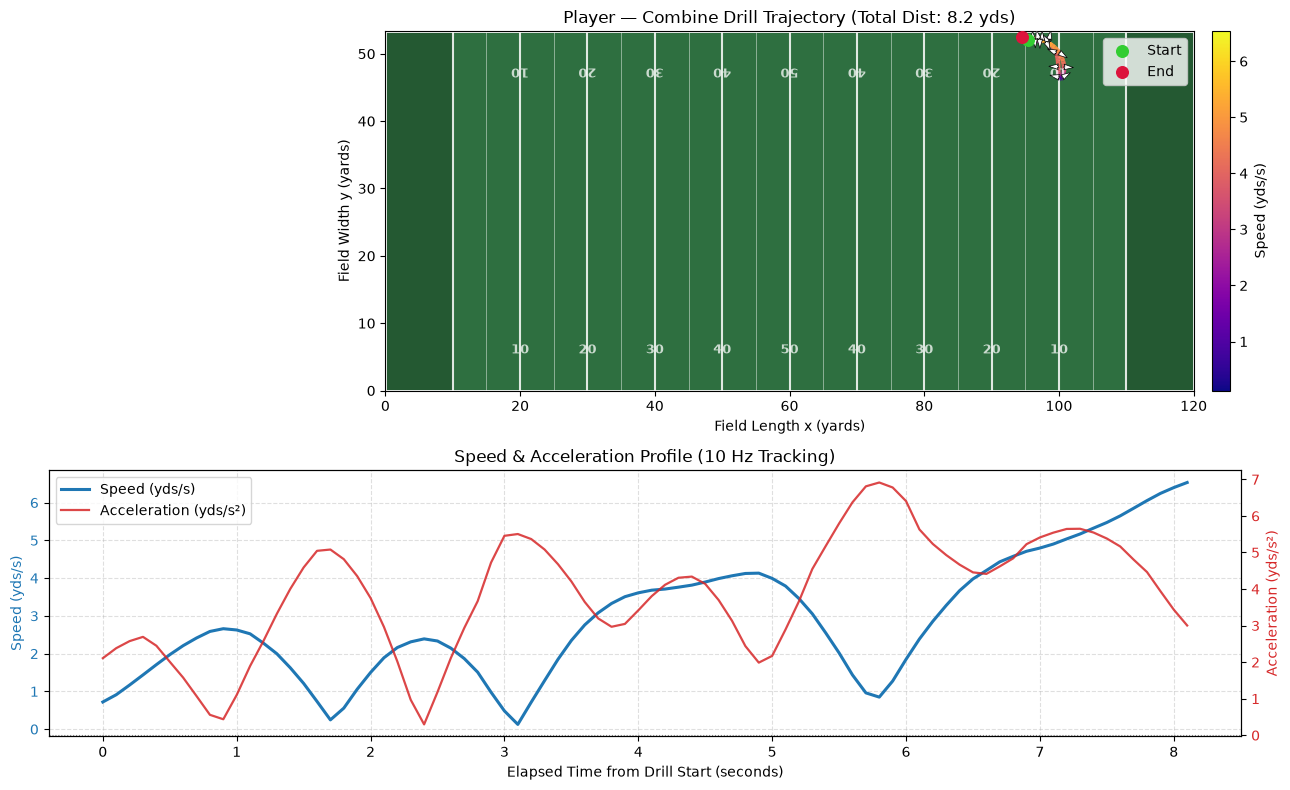

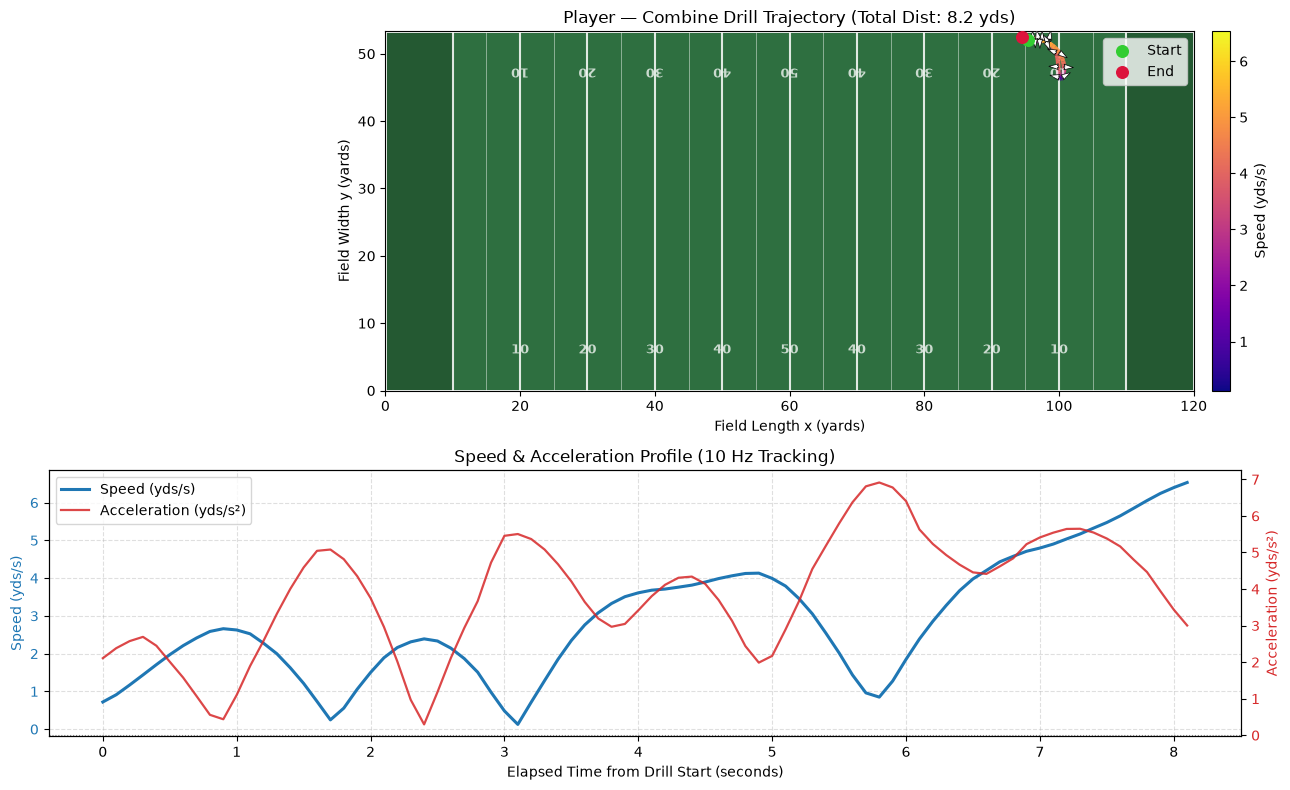

In [21]:
shuttle_samples_ = combine_df[combine_df["drill_name"] == "THREE_CONE_DRILL"].drop(columns=["draft_year", "drill_type", "entity_type"]).groupby(["event_id", "nfl_id", "attempt"], sort=False)
# three_cone_samples = samples[samples["drill_name"] == "THREE_CONE_DRILL"]
shuttle_samples = iter(shuttle_samples_)
n, df_ = next(shuttle_samples)
plot_combine_drill(df_)

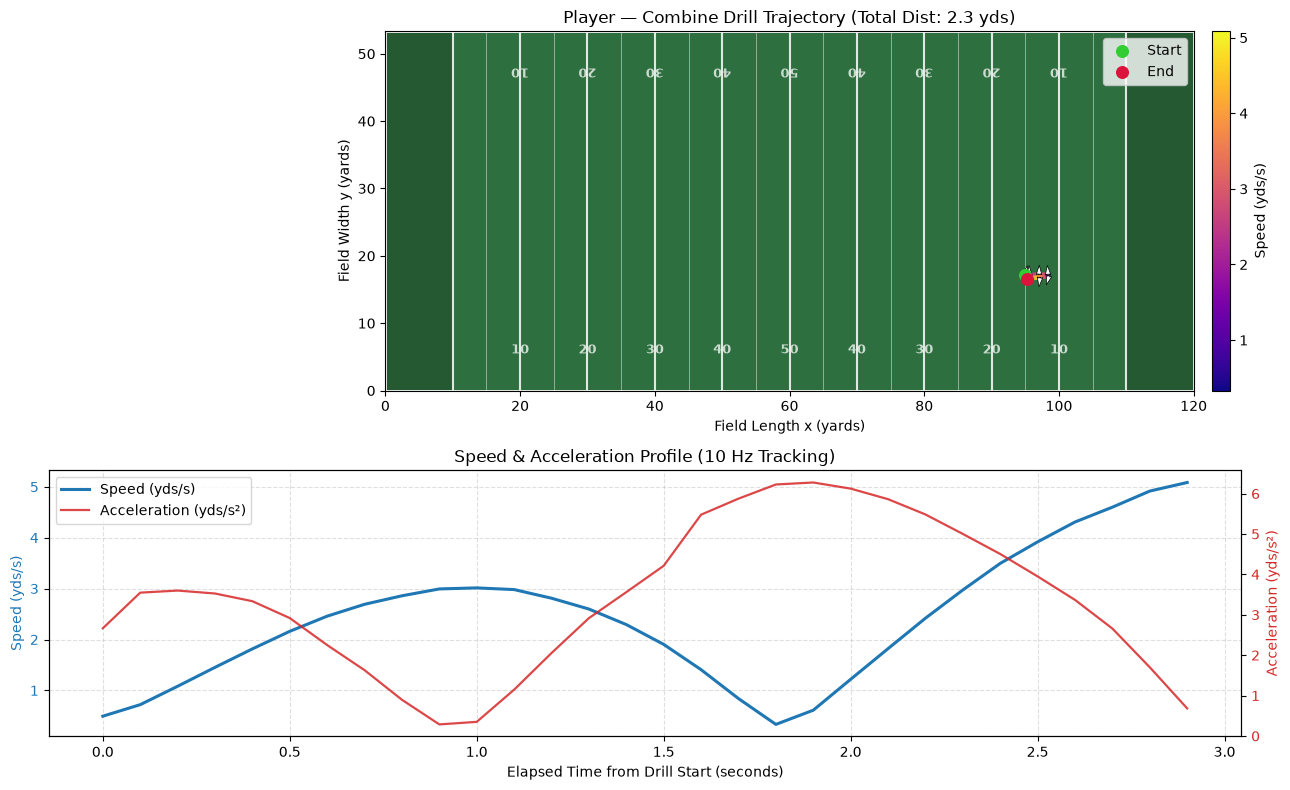

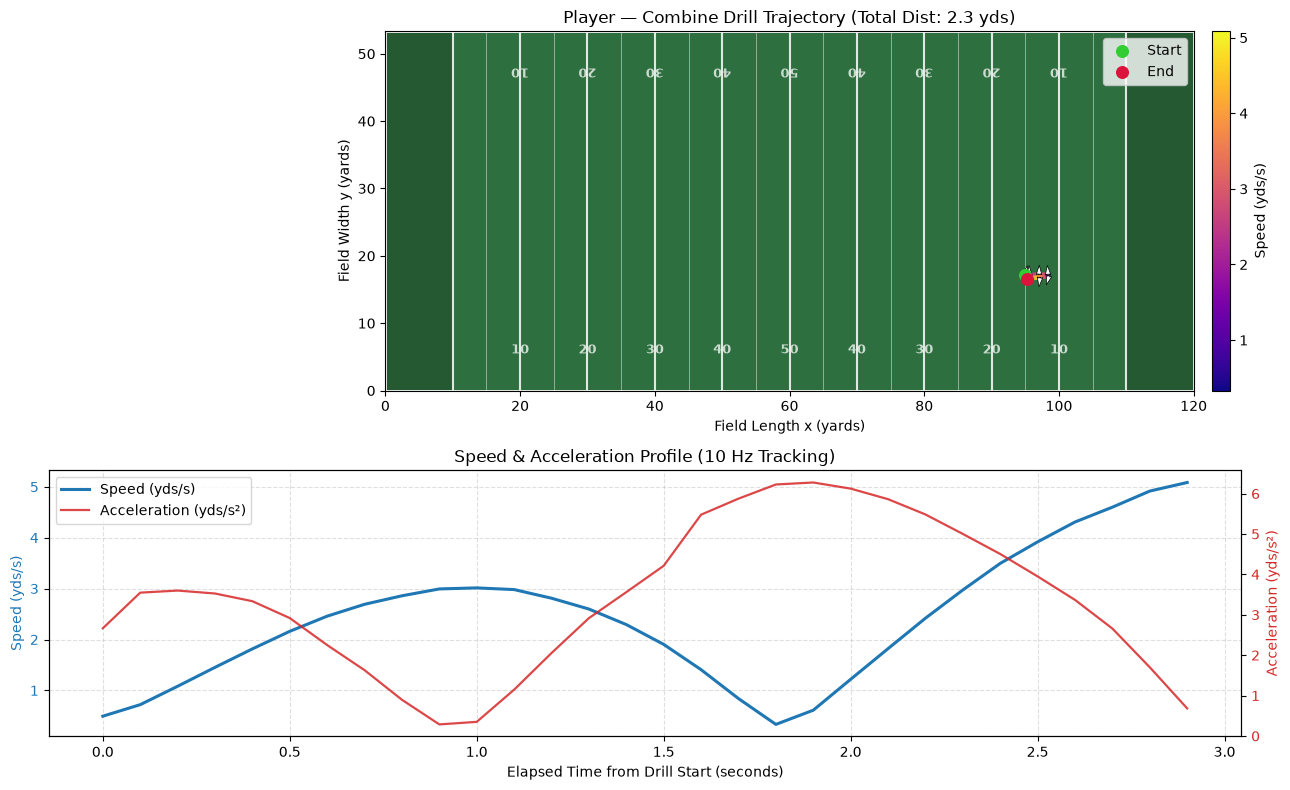

In [22]:
shuttle_samples_ = combine_df[combine_df["drill_name"] == "SHORT_SHUTTLE"].drop(columns=["draft_year", "drill_type", "entity_type"]).groupby(["event_id", "nfl_id", "attempt"], sort=False)
# three_cone_samples = samples[samples["drill_name"] == "THREE_CONE_DRILL"]
shuttle_samples = iter(shuttle_samples_)
n, df_ = next(shuttle_samples)
plot_combine_drill(df_)

In [23]:
df = df_.drop(columns=["event_id", "nfl_id", "drill_name", "attempt"]).copy()
df["frame"] = range(1,len(df)+1)
# pd.pivot(df, columns=["frame"], values=["x", "y", "s", "a", "dis", "dir"])
df.set_index("frame").T

frame,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
time,2025-03-02 21:13:20.700000,2025-03-02 21:13:20.800000,2025-03-02 21:13:20.900000,2025-03-02 21:13:21,2025-03-02 21:13:21.100000,2025-03-02 21:13:21.200000,2025-03-02 21:13:21.300000,2025-03-02 21:13:21.400000,2025-03-02 21:13:21.500000,2025-03-02 21:13:21.600000,...,2025-03-02 21:13:22.700000,2025-03-02 21:13:22.800000,2025-03-02 21:13:22.900000,2025-03-02 21:13:23,2025-03-02 21:13:23.100000,2025-03-02 21:13:23.200000,2025-03-02 21:13:23.300000,2025-03-02 21:13:23.400000,2025-03-02 21:13:23.500000,2025-03-02 21:13:23.600000
x,94.888072,94.948812,95.043864,95.18335,95.364126,95.591685,95.864207,96.133596,96.424255,96.729014,...,98.548147,98.395874,98.176534,97.899719,97.564768,97.192291,96.772664,96.328206,95.779327,95.213725
y,17.176617,17.184373,17.179652,17.145344,17.124914,17.146859,17.178416,17.187805,17.19605,17.201986,...,17.041892,17.000521,16.954678,16.908496,16.859717,16.813539,16.767852,16.72442,16.674844,16.633844
s,0.493748,0.720093,1.081096,1.452918,1.815643,2.160978,2.458603,2.691614,2.858644,2.993467,...,1.217935,1.820358,2.418338,2.972885,3.495,3.91754,4.308056,4.599398,4.915705,5.084277
a,2.665657,3.547709,3.599323,3.526631,3.335859,2.918116,2.250283,1.628742,0.895976,0.286563,...,6.122952,5.861814,5.483143,5.001384,4.504923,3.949977,3.368693,2.659183,1.700486,0.68276
dis,0.002961,0.00369,0.009035,0.019492,0.032683,0.051786,0.074275,0.07257,0.084483,0.092878,...,0.00874,0.02325,0.048156,0.076656,0.112217,0.138756,0.176099,0.197552,0.301278,0.319911
dir,71.876246,82.393165,88.50371,91.934021,91.862578,90.49896,89.120115,88.712496,88.440122,88.476248,...,252.512131,257.347622,259.801662,261.413007,262.498652,263.384126,264.106378,264.714854,265.240666,265.813754


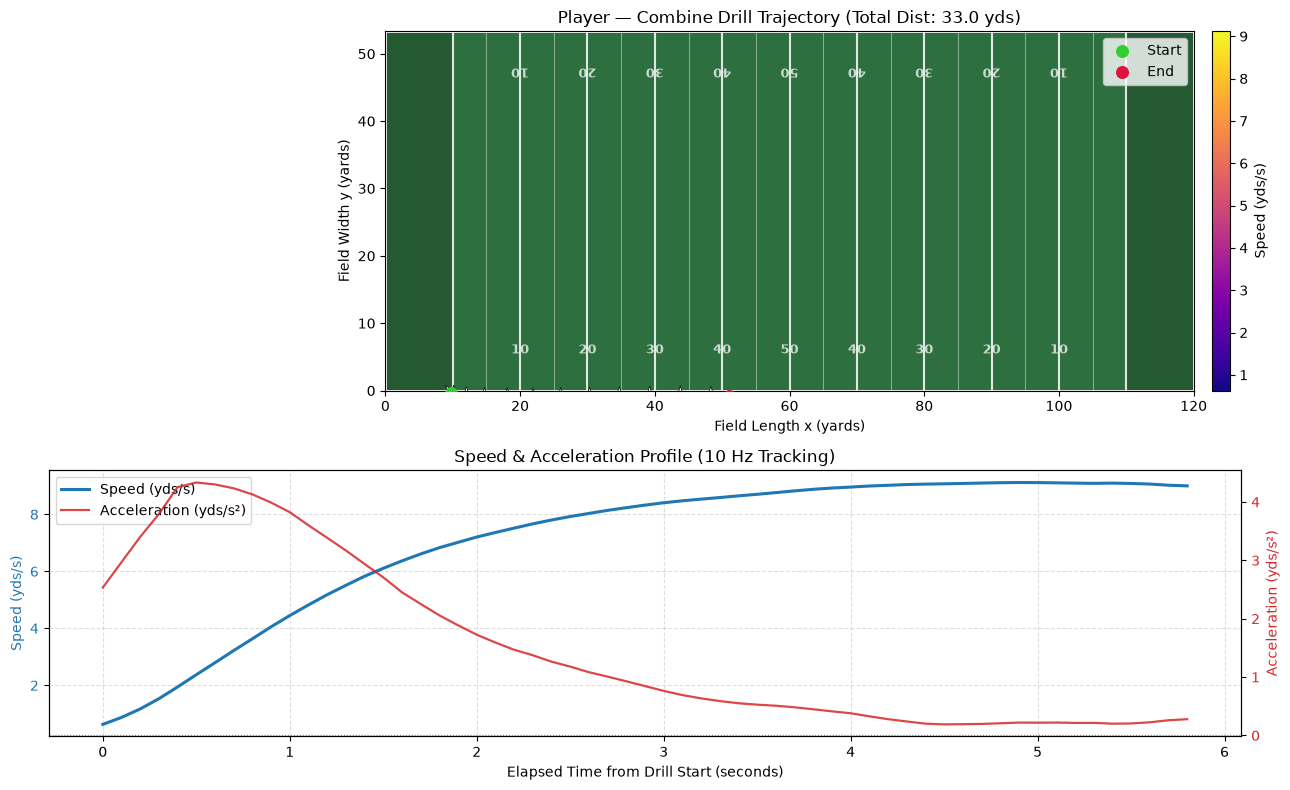

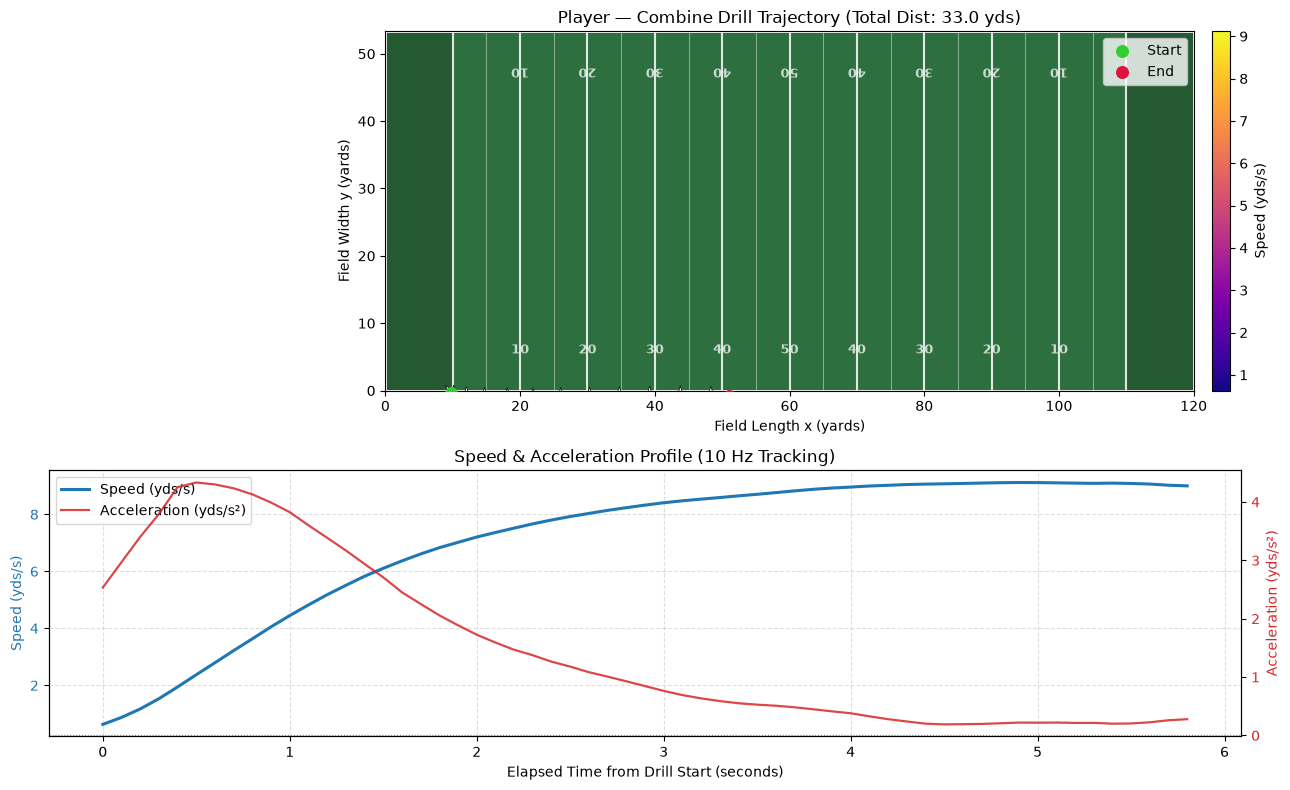

In [24]:
shuttle_samples_ = combine_df[combine_df["drill_name"] == "FORTY_YARD_DASH"].drop(columns=["draft_year", "drill_type", "entity_type"]).groupby(["event_id", "nfl_id", "attempt"], sort=False)
# three_cone_samples = samples[samples["drill_name"] == "THREE_CONE_DRILL"]
shuttle_samples = iter(shuttle_samples_)
n, df_ = next(shuttle_samples)
plot_combine_drill(df_)

In [25]:
combine_df["drill_name"].unique()

<StringArray>
[              'OL_PULL_DRILL_FOLD_BLOCK_RIGHT',
           'OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT',
                'OL_PULL_DRILL_LONG_PULL_RIGHT',
                               'PASS_RUSH_DROP',
                                 'SCREEN_DRILL',
                        'PASS_PRO-MIRROR_DRILL',
       'FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE',
                              'FORTY_YARD_DASH',
                             'THREE_CONE_DRILL',
                                'SHORT_SHUTTLE',
                           'RUN_THE_HOOP_DRILL',
                     'SHORT_ZONE_BREAK_FORWARD',
                  'SHORT_ZONE_BREAK_FLAT_WHEEL',
                      'SHORT_ZONE_BREAK_INSIDE',
                              'PASS_RUSH_DRILL',
                           'BODY_CONTROL_DRILL',
                       'FOUR_BAG_AGILITY_DRILL',
  'FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION',
                         'BACK_PEDAL_AND_REACT',
                           'RUN_AND_CLUB_DRILL',
      

In [26]:
combine_df["drill_type"].unique()

<StringArray>
[ 'SKILL_DRILLS_OL',  'FORTY_YARD_DASH', 'THREE_CONE_DRILL',
    'SHORT_SHUTTLE',  'SKILL_DRILLS_DL',  'SKILL_DRILLS_DB',
  'SKILL_DRILLS_TE',  'SKILL_DRILLS_WR',  'SKILL_DRILLS_LB']
Length: 9, dtype: str

In [27]:
combine_df[combine_df["drill_type"] == "SKILL_DRILLS_WR"]["drill_name"].unique()

<StringArray>
['POST_CORNER_ROUTE_RIGHT',          'GAUNTLET_DRILL',
    'OVER_SHOULDER_ADJUST',          'GO_ROUTE_RIGHT',
       'CIRCUS_ROUTE_LEFT',        'SLANT_ROUTE_LEFT',
    'SPEED_OUT_ROUTE_LEFT',        'CURL_ROUTE_RIGHT',
       'DAGGER_ROUTE_LEFT',  'SLOT_STRIKE_ROUTE_LEFT',
    'COMEBACK_ROUTE_RIGHT',   'SLOT_SAIL_ROUTE_RIGHT',
     'RED_ZONE_FADE_RIGHT',          'SPEED_OUT_LEFT',
  'POST_CORNER_ROUTE_LEFT']
Length: 15, dtype: str

In [28]:
def isolate_shuttle_phases(
    attempt_df: pd.DataFrame,
    acc_threshold: float = 1.5,    # yds/s^2 for acceleration bouts
    dec_threshold: float = -1.5,   # yds/s^2 (negative) for deceleration bouts
    min_frames: int = 3,           # 3 frames = 0.3s Minimum Effort Duration at 10 Hz
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Isolates acceleration and deceleration bouts for a single player drill attempt.
    Assumes 10 Hz tracking with columns: ['time', 'x', 'y', 's', 'a', 'dis', 'dir'].
    """
    df = attempt_df.sort_values("time").reset_index(drop=True).copy()
    dt = df["time"].diff().dt.total_seconds().fillna(0.1)

    # 1. Light rolling smoothing on speed to curb 10 Hz jitter before differencing
    df["s_smooth"] = df["s"].rolling(window=5, center=True, min_periods=1).mean()

    # 2. Signed longitudinal acceleration along the path (ds / dt)
    # Negative values indicate deceleration (braking); positive indicates speeding up.
    df["a_long"] = (df["s_smooth"].diff() / dt.replace(0, np.nan)).fillna(0.0)

    # Optional: velocity-vector dot product acceleration (captures directional + speed change)
    vx = df["x"].diff() / dt.replace(0, np.nan)
    vy = df["y"].diff() / dt.replace(0, np.nan)
    ax = vx.diff() / dt.replace(0, np.nan)
    ay = vy.diff() / dt.replace(0, np.nan)
    speed_vec = np.hypot(vx, vy)
    df["a_vec_long"] = np.where(
        speed_vec > 0.5,
        (vx * ax + vy * ay) / speed_vec,
        df["a_long"],
    )

    # 3. Classify each frame into a phase
    conditions = [
        df["a_long"] >= acc_threshold,
        df["a_long"] <= dec_threshold,
    ]
    df["phase"] = np.select(conditions, ["accel", "decel"], default="steady_or_transition")

    # 4. Assign contiguous bout IDs whenever phase or non-consecutive gap changes
    new_bout = (df["phase"] != df["phase"].shift()) | (dt > 0.15)
    df["bout_id"] = new_bout.cumsum()

    # 5. Aggregate each bout and enforce Minimum Effort Duration (MED)
    bouts = (
        df[df["phase"].isin(["accel", "decel"])]
        .groupby(["bout_id", "phase"], as_index=False)
        .agg(
            start_time=("time", "first"),
            end_time=("time", "last"),
            n_frames=("time", "count"),
            start_x=("x", "first"),
            end_x=("x", "last"),
            start_y=("y", "first"),
            end_y=("y", "last"),
            v_start=("s_smooth", "first"),
            v_end=("s_smooth", "last"),
            v_peak=("s_smooth", "max"),
            v_min=("s_smooth", "min"),
            a_mean=("a_long", "mean"),
            a_peak_mag=("a_long", lambda s: s.abs().max()),
            dist_yds=("dis", "sum"),
        )
    )
    bouts["duration_s"] = (bouts["end_time"] - bouts["start_time"]).dt.total_seconds() + 0.1
    bouts["delta_v"] = bouts["v_end"] - bouts["v_start"]
    bouts["braking_dist_per_yds_lost"] = np.where(
        (bouts["phase"] == "decel") & (bouts["delta_v"] < -0.25),
        bouts["dist_yds"] / bouts["delta_v"].abs(),
        np.nan,
    )

    bouts = bouts[bouts["n_frames"] >= min_frames].reset_index(drop=True)
    return df, bouts

In [29]:
res = isolate_shuttle_phases(df)
res[0]

,time,x,y,s,a,dis,dir,frame,s_smooth,a_long,a_vec_long,phase,bout_id
0,2025-03-02 21:13:20.700,94.888072,17.176617,0.493748,2.665657,0.002961,71.876246,1,0.764979,0.000000,0.000000,steady_or_transition,1
1,2025-03-02 21:13:20.800,94.948812,17.184373,0.720093,3.547709,0.003690,82.393165,2,0.936964,1.719847,NaN,accel,2
2,2025-03-02 21:13:20.900,95.043864,17.179652,1.081096,3.599323,0.009035,88.503710,3,1.112700,1.757358,3.488870,accel,2
3,2025-03-02 21:13:21.000,95.183350,17.145344,1.452918,3.526631,0.019492,91.934021,4,1.446145,3.334459,5.021421,accel,2
4,2025-03-02 21:13:21.100,95.364126,17.124914,1.815643,3.335859,0.032683,91.862578,5,1.793847,3.477020,3.947062,accel,2
5,2025-03-02 21:13:21.200,95.591685,17.146859,2.160978,2.918116,0.051786,90.498960,6,2.115951,3.221036,5.063531,accel,2
6,2025-03-02 21:13:21.300,95.864207,17.178416,2.458603,2.250283,0.074275,89.120115,7,2.397096,2.811453,4.576957,accel,2
7,2025-03-02 21:13:21.400,96.133596,17.187805,2.691614,1.628742,0.072570,88.712496,8,2.632661,2.355650,-0.390338,accel,2
8,2025-03-02 21:13:21.500,96.424255,17.196050,2.858644,0.895976,0.084483,88.440122,9,2.803242,1.705804,2.122976,accel,2
9,2025-03-02 21:13:21.600,96.729014,17.201986,2.993467,0.286563,0.092878,88.476248,10,2.907673,1.044318,1.405148,steady_or_transition,3


In [30]:
# sample = res[0].copy()
res[1]

,bout_id,phase,start_time,end_time,n_frames,start_x,end_x,start_y,end_y,v_start,v_end,v_peak,v_min,a_mean,a_peak_mag,dist_yds,duration_s,delta_v,braking_dist_per_yds_lost
0,2,accel,2025-03-02 21:13:20.800,2025-03-02 21:13:21.500,8,94.948812,96.424255,17.184373,17.196050,0.936964,2.803242,2.803242,0.936964,2.547828,3.477020,0.348013,0.8,1.866278,NaN
1,4,decel,2025-03-02 21:13:22.000,2025-03-02 21:13:22.400,5,97.923248,98.641459,17.207013,17.130170,2.517490,1.018856,2.517490,1.018856,-3.441188,4.531926,0.220919,0.5,-1.498635,0.147413
2,6,accel,2025-03-02 21:13:22.700,2025-03-02 21:13:23.500,9,98.548147,95.779327,17.041892,16.674844,1.279959,4.726859,4.726859,1.279959,4.180655,5.768217,1.082704,0.9,3.446900,NaN


In [31]:
combine_w_pos_df = pd.merge(combine_df, combine_results_df[["nfl_id", "combine_position"]], on="nfl_id")
shuttle_df = combine_w_pos_df[(combine_w_pos_df["drill_name"] == "SHORT_SHUTTLE") & (combine_w_pos_df["combine_position"].str.contains("wr|te", case=False))]
shuttle_df

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir,combine_position
35728,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.500,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.780548,18.338857,0.063562,0.277279,0.000382,139.074413,TE
35729,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.600,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.636220,18.345923,0.075792,0.509425,0.020831,207.993864,TE
35730,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.700,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.621358,18.343697,0.109470,0.713377,0.000221,180.660336,TE
35731,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.800,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.509857,18.300120,0.201982,1.010799,0.012577,201.466589,TE
35732,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.900,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.490692,18.256561,0.259172,1.289433,0.001933,177.326825,TE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
461095,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58.000,SHORT_SHUTTLE,SHORT_SHUTTLE,1,93.366667,11.066667,4.690000,5.203679,0.187830,98.176197,TE
461096,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58.100,SHORT_SHUTTLE,SHORT_SHUTTLE,1,93.866667,11.000000,5.200000,4.345629,0.250040,97.330050,TE
461097,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58.200,SHORT_SHUTTLE,SHORT_SHUTTLE,1,94.400000,10.933333,5.496667,2.924308,0.284479,96.021736,TE
461098,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58.300,SHORT_SHUTTLE,SHORT_SHUTTLE,1,94.966667,10.900000,5.756667,2.285962,0.321113,95.083280,TE


In [32]:
def run_shuttle_phases_across_attempts(
    shuttle_df: pd.DataFrame,
    acc_threshold: float = 1.5,
    dec_threshold: float = -1.5,
    min_frames: int = 3,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Applies `isolate_shuttle_phases()` to each shuttle attempt while retaining
    `nfl_id`, `event_id`, and `attempt` on every output row.
    """
    # Filter to PLAYER rows just in case BALL rows are present
    if "entity_type" in shuttle_df.columns:
        shuttle_df = shuttle_df[shuttle_df["entity_type"] == "PLAYER"].copy()

    frame_chunks = []
    bout_chunks = []

    group_cols = ["nfl_id", "event_id", "attempt"]
    for (nfl_id, event_id, attempt), attempt_df in shuttle_df.groupby(group_cols, dropna=False, sort=False):
        # Skip tiny/corrupted attempts that don't have enough frames to smooth
        if len(attempt_df) < 5:
            continue

        frames_out, bouts_out = isolate_shuttle_phases(
            attempt_df,
            acc_threshold=acc_threshold,
            dec_threshold=dec_threshold,
            min_frames=min_frames,
        )

        # Attach identifiers explicitly so nothing is lost or misaligned
        frames_out["nfl_id"] = nfl_id
        frames_out["event_id"] = event_id
        frames_out["attempt"] = attempt
        frame_chunks.append(frames_out)

        if not bouts_out.empty:
            bouts_out["nfl_id"] = nfl_id
            bouts_out["event_id"] = event_id
            bouts_out["attempt"] = attempt
            bout_chunks.append(bouts_out)

    all_frames = pd.concat(frame_chunks, ignore_index=True) if frame_chunks else pd.DataFrame()
    all_bouts = pd.concat(bout_chunks, ignore_index=True) if bout_chunks else pd.DataFrame()

    # Bring key identifiers to the front for readability
    id_cols = [c for c in ["nfl_id", "event_id", "attempt"] if c in all_bouts.columns]
    if not all_bouts.empty:
        other_cols = [c for c in all_bouts.columns if c not in id_cols]
        all_bouts = all_bouts[id_cols + other_cols]

    return all_frames, all_bouts

In [33]:
res = run_shuttle_phases_across_attempts(shuttle_df)
res[0]

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir,combine_position,s_smooth,a_long,a_vec_long,phase,bout_id
0,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.500,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.780548,18.338857,0.063562,0.277279,0.000382,139.074413,TE,0.082941,0.000000,0.000000,steady_or_transition,1
1,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.600,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.636220,18.345923,0.075792,0.509425,0.020831,207.993864,TE,0.112701,0.297602,NaN,steady_or_transition,1
2,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.700,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.621358,18.343697,0.109470,0.713377,0.000221,180.660336,TE,0.141995,0.292941,0.292941,steady_or_transition,1
3,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.800,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.509857,18.300120,0.201982,1.010799,0.012577,201.466589,TE,0.194458,0.524627,10.506090,steady_or_transition,1
4,2025,20250228100500_1740793859122_000,58424,PLAYER,2025-03-01 01:50:52.900,SHORT_SHUTTLE,SHORT_SHUTTLE,2,94.490692,18.256561,0.259172,1.289433,0.001933,177.326825,TE,0.268436,0.739781,0.739781,steady_or_transition,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3887,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58.000,SHORT_SHUTTLE,SHORT_SHUTTLE,1,93.366667,11.066667,4.690000,5.203679,0.187830,98.176197,TE,4.610000,5.293333,3.294573,accel,10
3888,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58.100,SHORT_SHUTTLE,SHORT_SHUTTLE,1,93.866667,11.000000,5.200000,4.345629,0.250040,97.330050,TE,5.056667,4.466667,6.608185,accel,10
3889,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58.200,SHORT_SHUTTLE,SHORT_SHUTTLE,1,94.400000,10.933333,5.496667,2.924308,0.284479,96.021736,TE,5.414667,3.580000,3.307593,accel,10
3890,2023,6414e6d3e3d8e72dcdcd045a-2023,56085,PLAYER,2023-03-05 00:55:58.300,SHORT_SHUTTLE,SHORT_SHUTTLE,1,94.966667,10.900000,5.756667,2.285962,0.321113,95.083280,TE,5.595833,1.811667,3.131842,accel,10


In [34]:
all_bouts = res[1].sort_values(["nfl_id", "event_id", "attempt", "start_time"]).copy()
all_bouts["bout_num_in_phase"] = all_bouts.groupby(["event_id", "phase"]).cumcount() + 1

In [35]:
with pd.option_context('display.max_columns', None):
    display(all_bouts.sort_values(by=['event_id', 'attempt', 'bout_id']).head(10))

,nfl_id,event_id,attempt,bout_id,phase,start_time,end_time,n_frames,start_x,end_x,start_y,end_y,v_start,v_end,v_peak,v_min,a_mean,a_peak_mag,dist_yds,duration_s,delta_v,braking_dist_per_yds_lost,bout_num_in_phase
216,57244,20240301100500_1709344335579_000,2,2,accel,2024-03-02 01:52:08.100,2024-03-02 01:52:08.700,7,95.300000,94.100000,16.466667,15.900000,1.195333,2.494667,2.494667,1.195333,2.096190,2.400000,0.298386,0.7,1.299333,NaN,1
217,57244,20240301100500_1709344335579_000,2,4,decel,2024-03-02 01:52:09.300,2024-03-02 01:52:09.700,5,92.433333,91.766667,15.866667,15.966667,2.360667,0.974000,2.360667,0.974000,-3.146667,4.446667,0.193430,0.5,-1.386667,0.139493,1
218,57244,20240301100500_1709344335579_000,2,6,accel,2024-03-02 01:52:09.900,2024-03-02 01:52:10.700,9,91.833333,94.633333,16.000000,15.900000,1.078000,4.861333,4.861333,1.078000,4.396296,6.266667,1.133397,0.9,3.783333,NaN,2
219,57244,20240301100500_1709344335579_000,2,8,decel,2024-03-02 01:52:11.100,2024-03-02 01:52:11.900,9,96.733333,98.966667,16.066667,16.633333,4.735333,1.137333,4.735333,1.137333,-4.196296,6.486667,1.036341,0.9,-3.598000,0.288033,2
220,57244,20240301100500_1709344335579_000,2,10,accel,2024-03-02 01:52:12.100,2024-03-02 01:52:12.900,9,98.833333,95.800000,16.700000,16.666667,1.490667,5.411333,5.411333,1.490667,4.709630,6.460000,1.282320,0.9,3.920667,NaN,3
221,57244,20240301100500_1709344437782_000,3,2,accel,2024-03-02 01:53:50.200,2024-03-02 01:53:51.000,9,96.033333,94.600000,16.733333,16.033333,0.552667,2.860000,2.860000,0.552667,2.782963,3.586667,0.359882,0.9,2.307333,NaN,1
222,57244,20240301100500_1709344437782_000,3,4,decel,2024-03-02 01:53:51.600,2024-03-02 01:53:52.100,6,92.766667,91.900000,15.800000,15.933333,2.700667,0.955333,2.700667,0.955333,-3.228889,4.513333,0.261258,0.6,-1.745333,0.149690,1
223,57244,20240301100500_1709344437782_000,3,6,accel,2024-03-02 01:53:52.300,2024-03-02 01:53:53.100,9,92.033333,95.033333,15.933333,15.800000,1.216000,5.009333,5.009333,1.216000,4.497037,6.566667,1.303501,0.9,3.793333,NaN,2
224,57244,20240301100500_1709344437782_000,3,8,decel,2024-03-02 01:53:53.400,2024-03-02 01:53:54.200,9,96.600000,98.866667,15.933333,16.733333,4.842000,1.297333,4.842000,1.297333,-4.124444,6.486667,1.108964,0.9,-3.544667,0.312854,2
225,57244,20240301100500_1709344437782_000,3,10,accel,2024-03-02 01:53:54.400,2024-03-02 01:53:55.300,10,98.700000,94.800000,16.800000,16.400000,1.696667,5.828889,5.828889,1.696667,4.482889,6.786667,1.840249,1.0,4.132222,NaN,3


In [36]:
dec_summary = (
    all_bouts[all_bouts["phase"] == "decel"]
    .groupby(["nfl_id", "event_id", "attempt"], as_index=False)
    .agg(
        n_dec_bouts=("bout_id", "count"),
        max_braking_mag=("a_peak_mag", "max"),
        mean_braking_mag=("a_peak_mag", "mean"),
        min_braking_dist_per_yds=("braking_dist_per_yds_lost", "min"),
    )
)

acc_summary = (
    all_bouts[all_bouts["phase"] == "accel"]
    .groupby(["nfl_id", "event_id", "attempt"], as_index=False)
    .agg(
        n_acc_bouts=("bout_id", "count"),
        max_accel_mean=("a_mean", "max"),
        max_speed_in_bout=("v_peak", "max"),
    )
)

attempt_metrics = pd.merge(dec_summary, acc_summary, on=["nfl_id", "event_id", "attempt"], how="outer")

# Things to Measure - shuttle
- Time to top speed from full deceleration
- Time at top speed before deceleration
- Top speed relative to 40yd top speed
- Top speed relative to 3-cone top speed
- Acceleration relative to 40yd acceleration
- Correlation between 3-cone cornering and shuttle CoD?
- Correlation between 3-cone turn (around the last cone) and shuttle CoD?
- Correlation between CoD time and route breaks?
    - Particularly comeback/hitch routes for shuttle, in/out routes for 3-cone
    - Do players who perform better on these drills gain better separation on these routes? Do they have more success on these routes in general?

## 3-cone
- Break the drill into phases:
    - First burst
    - First stop & turn
    - Second burst
    - Second stop & turn
    - Third burst
    - First corner
    - Fourth burst
    - Wheel
    - Fifth burst
    - Second corner
    - Final burst

In [37]:
attempt_metrics

,nfl_id,event_id,attempt,n_dec_bouts,max_braking_mag,mean_braking_mag,min_braking_dist_per_yds,n_acc_bouts,max_accel_mean,max_speed_in_bout
0,55915,6414e684e3d8e72dcdcb5029-2023,1,2.0,8.126667,6.690000,0.177381,3,5.028148,6.083333
1,55915,6414e684e3d8e72dcdcb5033-2023,2,2.0,7.873333,6.293333,0.169658,3,5.281852,6.021667
2,55943,6414e6d3e3d8e72dcdcd0470-2023,1,2.0,7.166667,5.853333,0.139359,3,5.452500,5.768667
3,55958,6414e6d3e3d8e72dcdcd0444-2023,1,2.0,6.166667,6.030000,0.151081,3,4.592593,5.180667
4,55958,6414e6d3e3d8e72dcdcd044a-2023,2,1.0,4.893333,4.893333,0.143663,2,4.712667,5.636667
...,...,...,...,...,...,...,...,...,...,...
68,58460,20250228100500_1740793791319_000,1,2.0,7.423815,6.200567,0.152126,3,5.117447,5.968624
69,58734,20250301100700_1740868168797_000,1,2.0,6.497096,5.777304,0.171159,3,4.771024,6.060628
70,58737,20250228100500_1740793645339_000,1,2.0,7.949584,6.342359,0.155306,3,5.373340,5.533120
71,58901,20250301100700_1740868142177_000,2,2.0,7.441555,5.747903,0.122652,3,5.394849,5.990632


In [38]:
def extract_40yd_kinematics_robust(
    forty_df: pd.DataFrame,
    combine_results_df: pd.DataFrame | None = None,
    acc_threshold: float = 1.5,
    start_speed_threshold: float = 0.5,
) -> pd.DataFrame:
    if "entity_type" in forty_df.columns:
        forty_df = forty_df[forty_df["entity_type"] == "PLAYER"].copy()

    rows = []
    group_cols = ["nfl_id", "event_id", "attempt"]

    for (nfl_id, event_id, attempt), g in forty_df.groupby(group_cols, dropna=False, sort=False):
        g = g.sort_values("time").reset_index(drop=True)
        if len(g) < 3:
            continue

        if np.issubdtype(g["time"].dtype, np.datetime64) or np.issubdtype(g["time"].dtype, np.timedelta64):
            t_rel = (g["time"] - g["time"].iloc[0]).dt.total_seconds().to_numpy()
        else:
            t_rel = (g["time"] - g["time"].iloc[0]).to_numpy(dtype=float)

        attempt_duration_s = float(t_rel[-1] - t_rel[0]) if len(t_rel) > 1 else np.nan
        s_smooth = g["s"].rolling(window=5, center=True, min_periods=1).mean().to_numpy()
        a_long = (
            np.gradient(s_smooth, t_rel)
            if len(t_rel) >= 2 and np.all(np.diff(t_rel) > 0)
            else np.zeros_like(s_smooth)
        )

        dis_arr = g["dis"].fillna(0.0).to_numpy()
        total_attempt_dist_yds = float(np.sum(dis_arr))

        active_idx = np.flatnonzero(s_smooth >= start_speed_threshold)
        start_idx = int(active_idx[0]) if len(active_idx) > 0 else 0
        t_start = t_rel[start_idx]

        cum_dist_from_start = np.cumsum(dis_arr) - np.cumsum(dis_arr)[start_idx]
        crossed_40 = np.flatnonzero(cum_dist_from_start >= 40.0)

        if len(crossed_40) > 0:
            end_idx = int(crossed_40[0])
            if end_idx > start_idx and cum_dist_from_start[end_idx] > cum_dist_from_start[end_idx - 1]:
                frac = (40.0 - cum_dist_from_start[end_idx - 1]) / (
                    cum_dist_from_start[end_idx] - cum_dist_from_start[end_idx - 1]
                )
                t_40 = t_rel[end_idx - 1] + frac * (t_rel[end_idx] - t_rel[end_idx - 1])
            else:
                t_40 = t_rel[end_idx]
            tracking_40yd_time_s = float(t_40 - t_start)
            time_method = "interp_40yd"
            sprint_mask = (np.arange(len(g)) >= start_idx) & (np.arange(len(g)) <= end_idx)
        else:
            # Fallback to full attempt window when 40-yd crossing isn't reached in tracking
            tracking_40yd_time_s = attempt_duration_s
            time_method = "window_fallback"
            sprint_mask = np.arange(len(g)) >= 0

        s_sprint = s_smooth[sprint_mask]
        a_sprint = a_long[sprint_mask]
        t_sprint = t_rel[sprint_mask]

        if len(s_sprint) == 0:
            continue

        v_peak = float(np.max(s_sprint))
        if pd.isna(v_peak) or v_peak <= 0:
            continue

        reach_90_pos = np.flatnonzero(s_sprint >= 0.90 * v_peak)
        if len(reach_90_pos) > 0:
            p90 = int(reach_90_pos[0])
            t_to_90pct = float(t_sprint[p90] - t_sprint[0])
        else:
            t_to_90pct = np.nan

        accel_mask = a_sprint >= acc_threshold
        mean_accel_drive = float(np.mean(a_sprint[accel_mask])) if np.any(accel_mask) else np.nan
        peak_accel = float(np.max(a_sprint))
        top_speed_mask = s_sprint >= 0.95 * v_peak
        mean_top_speed = float(np.mean(s_sprint[top_speed_mask])) if np.any(top_speed_mask) else v_peak

        rows.append({
            "nfl_id": nfl_id,
            "event_id": event_id,
            "attempt": attempt,
            "tracking_40yd_time_s": tracking_40yd_time_s,
            "attempt_duration_s": attempt_duration_s,
            "total_attempt_dist_yds": total_attempt_dist_yds,
            "time_method": time_method,
            "v_peak_yds": v_peak,
            "v_peak_mph": v_peak * 2.04545,
            "mean_top_speed_yds": mean_top_speed,
            "peak_accel_yds2": peak_accel,
            "mean_accel_drive_yds2": mean_accel_drive,
            "t_to_90pct_vpeak_s": t_to_90pct,
        })

    out = pd.DataFrame(rows)
    if combine_results_df is not None and not out.empty:
        cols_to_keep = [c for c in ["nfl_id", "forty", "ten_yd_split"] if c in combine_results_df.columns]
        if "nfl_id" in cols_to_keep:
            bench = combine_results_df[cols_to_keep].drop_duplicates(subset=["nfl_id"])
            out = out.merge(bench, on="nfl_id", how="left").rename(columns={"forty": "official_forty_s"})
    return out

In [39]:
def best_attempt_per_player(
    metrics_df: pd.DataFrame,
    metric_col: str,
    higher_is_better: bool = True,
) -> pd.DataFrame:
    """
    Returns one row per `nfl_id` corresponding to each player's best attempt
    on `metric_col` (preserving all other columns from that exact attempt).
    """
    valid = metrics_df.dropna(subset=[metric_col]).copy()
    if valid.empty:
        return pd.DataFrame(columns=metrics_df.columns)

    # Sort so the best attempt per player comes first
    valid = valid.sort_values(
        by=[metric_col, "attempt"],
        ascending=[not higher_is_better, True],
    )

    best_df = valid.drop_duplicates(subset=["nfl_id"], keep="first").reset_index(drop=True)
    return best_df

In [ ]:
forty_df = extract_40yd_kinematics_robust(combine_df[combine_df["drill_name"] == "FORTY_YARD_DASH"])
forty_df

,nfl_id,event_id,attempt,tracking_40yd_time_s,attempt_duration_s,total_attempt_dist_yds,time_method,v_peak_yds,v_peak_mph,mean_top_speed_yds,peak_accel_yds2,mean_accel_drive_yds2,t_to_90pct_vpeak_s
0,58896,20250302101000_1740946089384_000,1,5.8,5.8,33.023236,window_fallback,9.108454,18.630887,9.010662,4.212413,2.943364,2.8
1,58896,20250302101000_1740946604458_000,2,5.5,5.5,32.967082,window_fallback,9.239366,18.898661,9.075132,4.993053,3.247640,2.6
2,58261,20250302101000_1740946012561_000,1,6.0,6.0,33.140000,window_fallback,9.041241,18.493407,8.946827,4.260084,3.087830,2.9
3,58261,20250302101000_1740946523648_000,2,5.8,5.8,32.812886,window_fallback,9.136562,18.688381,9.015389,4.339912,3.108191,2.8
4,58454,20250302100900_1740939268259_000,1,5.7,5.7,33.807211,window_fallback,9.413043,19.253910,9.236641,4.223245,3.029490,2.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...
788,56085,6414e6d3e3d8e72dcdcd0313-2023,2,5.0,5.0,37.738049,window_fallback,10.942000,22.381314,10.776987,5.453333,3.239537,2.9
789,56010,640669e0e3d8e72dcdb59e26-2023,2,5.0,5.0,37.659169,window_fallback,10.711667,21.910179,10.539599,5.673333,3.876905,2.7
790,56010,640669e0e3d8e72dcdb59df2-2023,1,4.9,4.9,37.160274,window_fallback,10.746667,21.981769,10.571559,5.420000,3.601970,2.7
791,56040,6414e6d3e3d8e72dcdcd02ed-2023,1,5.1,5.1,35.048934,window_fallback,9.901333,20.252682,9.811011,5.156667,3.299533,2.3


In [ ]:
single_forty_df = forty_df.drop_duplicates(subset=["nfl_id"]).set_index("nfl_id")
single_shuttle_df = attempt_metrics.drop_duplicates(subset=["nfl_id"]).set_index("nfl_id")
# shuttle_forty_df = single_shuttle_df.join(single_forty_df, on="nfl_id", how="inner", suffixes=("_forty", "_shuttle"))
shuttle_forty_df = attempt_metrics.join(single_forty_df, on="nfl_id", how="inner", suffixes=("_forty", "_shuttle"))
with pd.option_context("display.max_columns", None):
    display(shuttle_forty_df)

,nfl_id,event_id_forty,attempt_forty,n_dec_bouts,max_braking_mag,mean_braking_mag,min_braking_dist_per_yds,n_acc_bouts,max_accel_mean,max_speed_in_bout,event_id_shuttle,attempt_shuttle,tracking_40yd_time_s,attempt_duration_s,total_attempt_dist_yds,time_method,v_peak_yds,v_peak_mph,mean_top_speed_yds,peak_accel_yds2,mean_accel_drive_yds2,t_to_90pct_vpeak_s
0,55915,6414e684e3d8e72dcdcb5029-2023,1,2.0,8.126667,6.690000,0.177381,3,5.028148,6.083333,6414e684e3d8e72dcdcb4d5f-2023,2,4.9,4.9,38.350791,window_fallback,10.996667,22.493132,10.836288,5.393333,3.471467,2.6
1,55915,6414e684e3d8e72dcdcb5033-2023,2,2.0,7.873333,6.293333,0.169658,3,5.281852,6.021667,6414e684e3d8e72dcdcb4d5f-2023,2,4.9,4.9,38.350791,window_fallback,10.996667,22.493132,10.836288,5.393333,3.471467,2.6
2,55943,6414e6d3e3d8e72dcdcd0470-2023,1,2.0,7.166667,5.853333,0.139359,3,5.452500,5.768667,6414e6d3e3d8e72dcdcd02f3-2023,2,5.0,5.0,35.611833,window_fallback,10.346667,21.163589,10.204475,5.670000,3.893377,2.8
3,55958,6414e6d3e3d8e72dcdcd0444-2023,1,2.0,6.166667,6.030000,0.151081,3,4.592593,5.180667,6414e6d3e3d8e72dcdcd0305-2023,1,4.8,4.8,36.814543,window_fallback,10.776667,22.043133,10.630078,5.773333,3.671364,2.7
4,55958,6414e6d3e3d8e72dcdcd044a-2023,2,1.0,4.893333,4.893333,0.143663,2,4.712667,5.636667,6414e6d3e3d8e72dcdcd0305-2023,1,4.8,4.8,36.814543,window_fallback,10.776667,22.043133,10.630078,5.773333,3.671364,2.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,58449,20250301100800_1740877443105_000,1,2.0,7.013966,5.693462,0.163129,3,4.708981,5.966392,20250301100800_1740870539260_000,1,4.9,4.9,39.565580,window_fallback,11.412451,23.343599,11.266314,5.436278,3.741974,3.1
69,58734,20250301100700_1740868168797_000,1,2.0,6.497096,5.777304,0.171159,3,4.771024,6.060628,20250301100700_1740861476575_000,1,5.1,5.1,38.052981,window_fallback,10.948849,22.395323,10.764320,5.526657,3.680185,2.8
70,58737,20250228100500_1740793645339_000,1,2.0,7.949584,6.342359,0.155306,3,5.373340,5.533120,20250228100500_1740788889046_000,2,5.2,5.2,36.133127,window_fallback,10.292740,21.053285,10.149848,4.960979,3.397645,2.7
71,58901,20250301100700_1740868142177_000,2,2.0,7.441555,5.747903,0.122652,3,5.394849,5.990632,20250301100700_1740862677028_000,2,4.9,4.9,38.959934,window_fallback,11.094926,22.694117,10.938057,5.581927,3.715200,2.7


In [42]:
shuttle_forty_df["shuttle_topspeed_pct"] = shuttle_forty_df["max_speed_in_bout"] / shuttle_forty_df["v_peak_yds"]

<Axes: xlabel='v_peak_yds', ylabel='shuttle_topspeed_pct'>

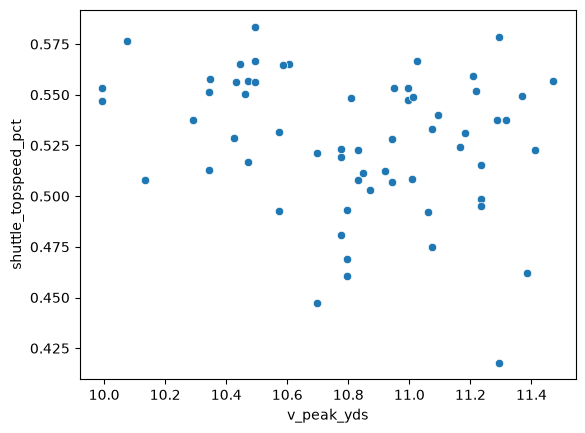

In [43]:
sns.scatterplot(data=shuttle_forty_df[shuttle_forty_df["nfl_id"] != 58424], x="v_peak_yds", y="shuttle_topspeed_pct")

In [44]:
shuttle_forty_df.loc[int(shuttle_forty_df["max_speed_in_bout"].idxmin())]

nfl_id                                                 58424
event_id_forty              20250228100500_1740793859122_000
attempt_forty                                              2
n_dec_bouts                                              NaN
max_braking_mag                                          NaN
mean_braking_mag                                         NaN
min_braking_dist_per_yds                                 NaN
n_acc_bouts                                                1
max_accel_mean                                      2.187794
max_speed_in_bout                                   1.622179
event_id_shuttle            20250228100500_1740789108046_000
attempt_shuttle                                            2
tracking_40yd_time_s                                     5.0
attempt_duration_s                                       5.0
total_attempt_dist_yds                             36.078935
time_method                                  window_fallback
v_peak_yds              

In [45]:
display(players_df[players_df["nfl_id"] == 58424])
combine_results_df[combine_results_df["nfl_id"] == 58424]

,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick
448,58424,Thomas Fidone,2025,TE,2002-09-20,Nebraska,Big Ten Conference,7.0,3.0,219.0


,draft_year,nfl_id,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
457,2025,58424,TE,77.0,243,10.625,34.0,82.625,1.57,4.7,35.5,126.0,7.01,4.29,NaN,75,67.0,72.0


In [47]:
def parse_three_cone_attempt(
    attempt_df: pd.DataFrame,
    acc_threshold: float = 1.5,
    dec_threshold: float = -1.5,
    turn_rate_threshold_deg_s: float = 45.0,
    min_frames: int = 3,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Parses a single 10 Hz 3-cone tracking attempt into kinematic signals and
    candidate movement segments (bursts, breakdowns, turns/corners).
    Expected columns: ['time', 'x', 'y', 's', 'a', 'dis', 'dir'].
    """
    df = attempt_df.sort_values("time").reset_index(drop=True).copy()

    # Relative time in seconds
    if np.issubdtype(df["time"].dtype, np.datetime64) or np.issubdtype(df["time"].dtype, np.timedelta64):
        t_rel = (df["time"] - df["time"].iloc[0]).dt.total_seconds().to_numpy()
    else:
        t_rel = (df["time"] - df["time"].iloc[0]).to_numpy(dtype=float)

    dt = np.diff(t_rel, prepend=t_rel[0])
    dt = np.where(dt <= 0, 0.1, dt)
    df["t_rel"] = t_rel

    # 1. Smooth speed and compute signed longitudinal acceleration (ds / dt)
    df["s_smooth"] = df["s"].rolling(window=5, center=True, min_periods=1).mean()
    s_arr = df["s_smooth"].to_numpy()
    df["a_long"] = np.gradient(s_arr, t_rel) if len(t_rel) >= 2 and np.all(np.diff(t_rel) > 0) else 0.0

    # 2. Unwrap heading (`dir`) in radians to compute angular turn rate (deg/s)
    if "dir" in df.columns and df["dir"].notna().any():
        dir_rad_unwrapped = np.unwrap(np.deg2rad(df["dir"].interpolate(limit_direction="both").to_numpy()))
        turn_rate_rad_s = np.gradient(dir_rad_unwrapped, t_rel) if len(t_rel) >= 2 else np.zeros_like(dir_rad_unwrapped)
        df["turn_rate_deg_s"] = np.rad2deg(turn_rate_rad_s)
        df["abs_turn_rate_deg_s"] = np.abs(df["turn_rate_deg_s"])
        df["cum_abs_turn_deg"] = np.cumsum(np.abs(np.rad2deg(np.diff(dir_rad_unwrapped, prepend=dir_rad_unwrapped[0]))))
    else:
        df["turn_rate_deg_s"] = 0.0
        df["abs_turn_rate_deg_s"] = 0.0
        df["cum_abs_turn_deg"] = 0.0

    # 3. Classify frame-level movement regime:
    #    - 'turn_or_corner': significant directional change while moving
    #    - 'breakdown': strong deceleration
    #    - 'burst': strong acceleration
    #    - 'other': steady/transition
    is_turning = (df["abs_turn_rate_deg_s"] >= turn_rate_threshold_deg_s) & (df["s_smooth"] >= 1.0)
    is_decel = (~is_turning) & (df["a_long"] <= dec_threshold)
    is_accel = (~is_turning) & (df["a_long"] >= acc_threshold)

    df["regime"] = np.select(
        [is_turning, is_decel, is_accel],
        ["turn_or_corner", "breakdown", "burst"],
        default="other",
    )

    # 4. Group contiguous regimes into segments
    new_seg = (df["regime"] != df["regime"].shift()) | (dt > 0.15)
    df["seg_id"] = new_seg.cumsum()

    segs = (
        df[df["regime"] != "other"]
        .groupby(["seg_id", "regime"], as_index=False)
        .agg(
            t_start=("t_rel", "first"),
            t_end=("t_rel", "last"),
            n_frames=("t_rel", "count"),
            x_start=("x", "first"),
            x_end=("x", "last"),
            y_start=("y", "first"),
            y_end=("y", "last"),
            v_start=("s_smooth", "first"),
            v_end=("s_smooth", "last"),
            v_peak=("s_smooth", "max"),
            v_min=("s_smooth", "min"),
            a_long_mean=("a_long", "mean"),
            peak_decel_mag=("a_long", lambda s: float(np.abs(np.min(s))) if len(s) > 0 else np.nan),
            peak_accel_mag=("a_long", lambda s: float(np.max(s)) if len(s) > 0 else np.nan),
            peak_turn_rate_deg_s=("abs_turn_rate_deg_s", "max"),
            net_turn_deg=("turn_rate_deg_s", lambda s: float(np.sum(s) * 0.1)),
            dist_yds=("dis", "sum"),
        )
    )
    segs["delta_v"] = segs["v_end"] - segs["v_start"]
    segs = segs[segs["n_frames"] >= min_frames].reset_index(drop=True)
    segs["seq_order"] = np.arange(1, len(segs) + 1)

    return df, segs

In [78]:
res = parse_three_cone_attempt(combine_w_pos_df[combine_w_pos_df["drill_name"] == "THREE_CONE_DRILL"])
event_segs = res[0][res[0]["event_id"] == "6407d3f0e3d8e72dcdb2faed-2023"]["seg_id"].to_list()
with pd.option_context("display.max_columns", None):
    display(res[1].loc[res[1]["seg_id"].isin(event_segs)])

,seg_id,regime,t_start,t_end,n_frames,x_start,x_end,y_start,y_end,v_start,v_end,v_peak,v_min,a_long_mean,peak_decel_mag,peak_accel_mag,peak_turn_rate_deg_s,net_turn_deg,dist_yds,delta_v,seq_order
0,2,burst,0.2,0.6,5,95.600000,96.433333,51.633333,51.766667,1.208667,2.273333,2.273333,1.208667,2.417167,1.750000,3.010000,8.169589,1.864049,0.201311,1.064667,1
1,4,breakdown,1.1,1.6,6,97.666667,98.400000,51.966667,52.100000,2.167333,0.724667,2.167333,0.724667,-2.593333,3.556667,-1.543333,669.289215,-74.701403,0.164652,-1.442667,2
2,6,burst,1.9,2.1,3,98.200000,97.900000,52.066667,52.000000,0.957333,1.576667,1.576667,0.957333,2.752222,2.336667,3.096667,55.215323,-6.854788,0.063425,0.619333,3
3,14,burst,3.3,3.8,6,96.833333,98.133333,51.566667,51.133333,1.544000,3.390000,3.390000,1.544000,3.568889,1.970000,4.600000,39.934001,5.876036,0.366618,1.846000,4
4,15,turn_or_corner,3.9,4.6,8,98.466667,100.000000,50.966667,48.900000,3.551333,3.782000,3.782000,3.551333,0.371250,0.130000,1.253333,73.400513,51.938115,0.938625,0.230667,5
5,17,breakdown,4.9,5.1,3,100.166667,100.200000,47.766667,47.133333,3.458667,2.778667,3.458667,2.778667,-3.352222,4.196667,-2.460000,23.966358,-1.096793,0.335566,-0.680000,6
6,18,turn_or_corner,5.2,7.2,21,100.233333,98.300000,46.866667,51.233333,2.320667,5.451333,5.451333,1.360000,1.415397,4.590000,4.076667,389.592664,-243.075030,2.246811,3.130667,7
7,20,breakdown,7.6,7.8,3,96.066667,94.866667,51.800000,51.900000,5.937333,3.941333,5.937333,3.941333,-8.109240,9.980000,-4.570000,30.018368,-7.948455,1.080168,-1.996000,8


In [79]:
with pd.option_context("display.max_columns", None):
    display(res[0][res[0]["event_id"] == "6407d3f0e3d8e72dcdb2faed-2023"])

,draft_year,event_id,nfl_id,entity_type,time,drill_type,drill_name,attempt,x,y,s,a,dis,dir,combine_position,t_rel,s_smooth,a_long,turn_rate_deg_s,abs_turn_rate_deg_s,cum_abs_turn_deg,regime,seg_id
0,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:26.600,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.400000,51.566667,0.620000,2.061394,0.004444,77.304635,DL,0.0,0.916667,1.375000,1.436662,1.436662,0.000000,other,1
1,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:26.700,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.466667,51.600000,0.906667,2.274985,0.004581,77.448301,DL,0.1,1.054167,1.460000,2.948544,2.948544,0.143666,other,1
2,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:26.800,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.600000,51.633333,1.223333,2.445531,0.017812,77.894344,DL,0.2,1.208667,2.279167,1.738947,1.738947,0.589709,burst,2
3,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:26.900,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.733333,51.633333,1.466667,2.559386,0.017778,77.796091,DL,0.3,1.510000,3.010000,4.697123,4.697123,0.687962,burst,2
4,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:27.000,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.966667,51.666667,1.826667,2.468335,0.054456,78.833769,DL,0.4,1.810667,2.733333,8.169589,8.169589,1.725639,burst,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:34.000,THREE_CONE_DRILL,THREE_CONE_DRILL,1,97.233333,51.566667,5.746667,3.847870,0.284999,284.479638,DL,7.4,5.720667,1.206667,-38.546421,38.546421,666.592527,other,19
75,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:34.100,THREE_CONE_DRILL,THREE_CONE_DRILL,1,96.666667,51.700000,5.840000,3.542280,0.321603,280.822539,DL,7.5,5.834000,1.083333,-34.180610,34.180610,670.249627,other,19
76,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:34.200,THREE_CONE_DRILL,THREE_CONE_DRILL,1,96.066667,51.800000,5.936667,3.113178,0.360139,277.643516,DL,7.6,5.937333,-4.570000,-30.018368,30.018368,673.428649,breakdown,20
77,2023,6407d3f0e3d8e72dcdb2faed-2023,55914,PLAYER,2023-03-02 21:29:34.300,THREE_CONE_DRILL,THREE_CONE_DRILL,1,95.466667,51.833333,6.033333,2.823811,0.360002,274.818865,DL,7.7,4.920000,-9.980000,-25.911861,25.911861,676.253300,breakdown,20


In [80]:
PHASE_SEQUENCE = [
    "first_burst",
    "first_stop_and_turn",
    "second_burst",
    "second_stop_and_turn",
    "third_burst",
    "first_corner",
    "fourth_burst",
    "wheel",
    "fifth_burst",
    "second_corner",
    "final_burst",
]


def _unwrap_heading_deg(series: pd.Series) -> np.ndarray:
    """Safely unwraps 0-360 degree headings so wrap-arounds don't spike turn rates."""
    valid = series.interpolate(method="linear", limit_direction="both").to_numpy(dtype=float)
    rad = np.deg2rad(valid)
    return np.rad2deg(np.unwrap(rad))


def prepare_three_cone_kinematics(attempt_df: pd.DataFrame) -> pd.DataFrame:
    """Computes smoothed speed, longitudinal accel, and turning rate for one 3-cone attempt."""
    df = attempt_df.sort_values("time").reset_index(drop=True).copy()

    if np.issubdtype(df["time"].dtype, np.datetime64) or np.issubdtype(df["time"].dtype, np.timedelta64):
        t_rel = (df["time"] - df["time"].iloc[0]).dt.total_seconds().to_numpy()
    else:
        t_rel = (df["time"] - df["time"].iloc[0]).to_numpy(dtype=float)

    dt = np.diff(t_rel, prepend=t_rel[0])
    dt = np.where(dt <= 0, 0.1, dt)

    df["t_rel"] = t_rel
    df["dt"] = dt
    df["s_smooth"] = df["s"].rolling(window=5, center=True, min_periods=1).mean()
    df["a_long"] = (df["s_smooth"].diff() / pd.Series(dt)).fillna(0.0)
    df["cum_dist"] = df["dis"].fillna(0.0).cumsum()

    if "dir" in df.columns and df["dir"].notna().any():
        heading_unwrapped = _unwrap_heading_deg(df["dir"])
        d_heading = np.diff(heading_unwrapped, prepend=heading_unwrapped[0])
        df["turn_rate_deg_s"] = np.abs(d_heading) / dt
        df["signed_turn_deg"] = d_heading
    else:
        # Fallback turning rate from (x, y) velocity vector angle if `dir` is missing
        dx = df["x"].diff().to_numpy(dtype=float)
        dy = df["y"].diff().to_numpy(dtype=float)
        angles = np.unwrap(np.arctan2(dy, dx))
        d_angles = np.rad2deg(np.diff(angles, prepend=angles[0]))
        df["turn_rate_deg_s"] = np.abs(d_angles) / dt
        df["signed_turn_deg"] = d_angles

    df["turn_rate_smooth"] = (
        df["turn_rate_deg_s"].rolling(window=5, center=True, min_periods=1).mean()
    )
    return df

def parse_three_cone_phases(attempt_df: pd.DataFrame) -> pd.DataFrame:
    """
    Labels each frame of a single 3-cone attempt into one of the 11 drill phases
    when 5 major turn/stop landmarks are detected.
    """
    df = prepare_three_cone_kinematics(attempt_df)
    n = len(df)
    df["phase"] = "unclassified"
    if n < 15:
        return df

    s = df["s_smooth"].to_numpy()
    w = df["turn_rate_smooth"].to_numpy()
    t = df["t_rel"].to_numpy()

    # Candidate landmark score: combines local speed dip + turning activity
    # Higher score = stronger candidate for a stop/turn or cone bend
    s_norm = (s.max() - s) / max(s.max() - s.min(), 1e-6)
    w_norm = (w - w.min()) / max(w.max() - w.min(), 1e-6)
    landmark_score = 0.55 * s_norm + 0.45 * w_norm

    # Greedily select up to 5 landmarks separated by at least 0.6s
    order = np.argsort(-landmark_score)
    selected_centers = []
    for idx in order:
        if all(abs(t[idx] - t[c]) >= 0.6 for c in selected_centers):
            selected_centers.append(int(idx))
        if len(selected_centers) == 5:
            break

    selected_centers = sorted(selected_centers)
    if len(selected_centers) < 5:
        return df

    # Build a small window (+/- 2 frames = +/- 0.2s) around each of the 5 ordered landmarks
    landmark_names = [
        "first_stop_and_turn",
        "second_stop_and_turn",
        "first_corner",
        "wheel",
        "second_corner",
    ]
    burst_names = [
        "first_burst",
        "second_burst",
        "third_burst",
        "fourth_burst",
        "fifth_burst",
        "final_burst",
    ]

    # Default all frames to bursts based on chronological landmark centers
    boundaries = [0] + selected_centers + [n]
    for i, b_name in enumerate(burst_names):
        start_i, end_i = boundaries[i], boundaries[i + 1]
        df.loc[start_i:end_i, "phase"] = b_name

    # Overwrite the immediate turn/corner window around each landmark center
    half_win = 2
    for center_i, l_name in zip(selected_centers, landmark_names):
        lo = max(0, center_i - half_win)
        hi = min(n, center_i + half_win + 1)
        df.loc[lo:hi, "phase"] = l_name

    return df

def summarize_three_cone_phases(all_three_cone_df: pd.DataFrame) -> pd.DataFrame:
    """Aggregates kinematics per attempt and 3-cone phase."""
    valid = all_three_cone_df[all_three_cone_df["phase"] != "unclassified"].copy()
    valid["decel_mag"] = np.where(valid["a_long"] < 0, valid["a_long"].abs(), np.nan)

    summary = (
        valid.groupby(["nfl_id", "event_id", "attempt", "phase"], as_index=False)
        .agg(
            n_frames=("t_rel", "count"),
            duration_s=("dt", "sum"),
            dist_yds=("dis", "sum"),
            s_start=("s_smooth", "first"),
            s_end=("s_smooth", "last"),
            s_min=("s_smooth", "min"),
            s_max=("s_smooth", "max"),
            peak_braking_yds2=("decel_mag", "max"),
            mean_braking_yds2=("decel_mag", "mean"),
            peak_accel_yds2=("a_long", "max"),
            max_turn_rate_deg_s=("turn_rate_deg_s", "max"),
            total_turn_deg=("signed_turn_deg", lambda s: float(np.abs(s).sum())),
        )
    )
    summary["speed_drop_yds_s"] = summary["s_max"] - summary["s_min"]
    summary["speed_gain_yds_s"] = summary["s_end"] - summary["s_start"]
    return summary


def parse_all_three_cone_attempts(three_cone_df: pd.DataFrame) -> pd.DataFrame:
    """
    Applies `parse_three_cone_phases()` to each 3-cone attempt individually
    and concatenates all attempts into one dataframe.
    """
    if "entity_type" in three_cone_df.columns:
        three_cone_df = three_cone_df[three_cone_df["entity_type"] == "PLAYER"].copy()

    parsed_chunks = []
    group_cols = ["nfl_id", "event_id", "attempt"]

    for (nfl_id, event_id, attempt), attempt_df in three_cone_df.groupby(
        group_cols, dropna=False, sort=False
    ):
        if len(attempt_df) < 15:
            continue

        out = parse_three_cone_phases(attempt_df)
        out["nfl_id"] = nfl_id
        out["event_id"] = event_id
        out["attempt"] = attempt
        parsed_chunks.append(out)

    if not parsed_chunks:
        return pd.DataFrame()

    all_parsed = pd.concat(parsed_chunks, ignore_index=True)

    # Move identifiers to the front
    id_cols = [c for c in ["nfl_id", "event_id", "attempt"] if c in all_parsed.columns]
    other_cols = [c for c in all_parsed.columns if c not in id_cols]
    return all_parsed[id_cols + other_cols]



In [81]:
all_3cone_frames = parse_all_three_cone_attempts(combine_w_pos_df[(combine_w_pos_df["drill_name"] == "THREE_CONE_DRILL") & (combine_w_pos_df["combine_position"].str.contains("wr|te", case=False))])
all_3cone_phase_summary = summarize_three_cone_phases(all_3cone_frames)


In [82]:
all_3cone_phase_summary

,nfl_id,event_id,attempt,phase,n_frames,duration_s,dist_yds,s_start,s_end,s_min,s_max,peak_braking_yds2,mean_braking_yds2,peak_accel_yds2,max_turn_rate_deg_s,total_turn_deg,speed_drop_yds_s,speed_gain_yds_s
0,55943,6414e6d3e3d8e72dcdcd044c-2023,1,fifth_burst,21,2.1,2.630541,2.481333,2.168667,2.168667,4.218667,5.580000,3.416667,3.960000,89.215675,106.212837,2.050000,-0.312667
1,55943,6414e6d3e3d8e72dcdcd044c-2023,1,final_burst,22,2.2,4.012969,2.755333,5.116667,2.755333,5.116667,NaN,NaN,4.066667,76.709184,125.754507,2.361333,2.361333
2,55943,6414e6d3e3d8e72dcdcd044c-2023,1,first_corner,6,0.6,0.108950,1.043333,1.724000,0.798000,1.724000,3.806667,2.086667,4.133333,1616.199409,178.716950,0.926000,0.680667
3,55943,6414e6d3e3d8e72dcdcd044c-2023,1,first_stop_and_turn,4,0.4,0.041778,0.784444,1.386667,0.784444,1.386667,NaN,NaN,3.026667,136.873619,31.394240,0.602222,0.602222
4,55943,6414e6d3e3d8e72dcdcd044c-2023,1,fourth_burst,7,0.7,0.346724,2.051333,1.410000,1.410000,2.328667,4.080000,2.296667,3.273333,33.373098,8.942165,0.918667,-0.641333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
520,58998,20250228100500_1740793746554_000,1,fourth_burst,6,0.6,0.154267,1.298979,1.115808,1.115808,1.488333,2.152297,1.241751,2.322099,20.743821,5.697986,0.372525,-0.183171
521,58998,20250228100500_1740793746554_000,1,second_corner,6,0.6,0.139833,1.436736,2.433375,1.198282,2.433375,4.598433,3.491488,5.455674,594.707190,152.652481,1.235093,0.996639
522,58998,20250228100500_1740793746554_000,1,second_stop_and_turn,6,0.6,0.211349,1.247573,1.821093,1.247573,1.825974,0.048813,0.048813,2.233757,33.979087,15.020697,0.578401,0.573520
523,58998,20250228100500_1740793746554_000,1,third_burst,3,0.3,0.090347,1.732367,1.298278,1.298278,1.732367,2.585567,1.742716,-0.887263,7.985992,1.210732,0.434088,-0.434088


In [84]:
named_3cone = all_3cone_phase_summary.join(players_df.set_index("nfl_id")["display_name"], on="nfl_id", how="left", suffixes=("_phase", "_player")).join(combine_results_df.set_index("nfl_id")["combine_position"], on="nfl_id", how="left", suffixes=("_phase", "_combine"))

In [73]:
named_3cone["phase"].unique()

<StringArray>
[         'fifth_burst',          'final_burst',         'first_corner',
  'first_stop_and_turn',         'fourth_burst',         'second_burst',
        'second_corner', 'second_stop_and_turn',                'wheel',
          'third_burst',          'first_burst']
Length: 11, dtype: str

In [86]:
named_3cone[named_3cone["phase"] == "first_stop_and_turn"].sort_values(by="speed_drop_yds_s", ascending=False).head(10)

,nfl_id,event_id,attempt,phase,n_frames,duration_s,dist_yds,s_start,s_end,s_min,s_max,peak_braking_yds2,mean_braking_yds2,peak_accel_yds2,max_turn_rate_deg_s,total_turn_deg,speed_drop_yds_s,speed_gain_yds_s,display_name,combine_position
510,58901,20250301100700_1740868457809_000,1,first_stop_and_turn,6,0.6,0.032814,0.331706,1.284409,0.331706,1.284409,0.090439,0.090439,3.546155,438.452340,149.295470,0.952703,0.952703,Da'Quan Felton,WR
120,57130,20240302100800_1709426547011_000,3,first_stop_and_turn,4,0.4,0.091111,1.141111,1.983333,1.141111,1.983333,NaN,NaN,4.106667,10.823168,2.524028,0.842222,0.842222,Rome Odunze,WR
111,57130,20240302100800_1709426415538_000,2,first_stop_and_turn,4,0.4,0.046826,0.886667,1.652000,0.886667,1.652000,NaN,NaN,3.793333,15.815504,3.901313,0.765333,0.765333,Rome Odunze,WR
101,57130,20240302100800_1709426308351_000,1,first_stop_and_turn,4,0.4,0.026701,0.623333,1.378667,0.623333,1.378667,NaN,NaN,3.813333,13.000311,3.084555,0.755333,0.755333,Rome Odunze,WR
222,57223,20240302100700_1709417093755_000,1,first_stop_and_turn,4,0.4,0.051111,0.877778,1.617333,0.877778,1.617333,NaN,NaN,3.593333,39.884963,8.342636,0.739556,0.739556,Troy Franklin,WR
21,55990,6414e5fde3d8e72dcdc8d583-2023,3,first_stop_and_turn,4,0.4,0.034027,0.747778,1.482667,0.747778,1.482667,NaN,NaN,3.593333,145.608510,31.531756,0.734889,0.734889,Derius Davis,WR
66,56112,6414e6d3e3d8e72dcdcd047e-2023,3,first_stop_and_turn,4,0.4,0.047223,0.875556,1.596000,0.875556,1.596000,NaN,NaN,3.613333,105.679350,20.589319,0.720444,0.720444,Brayden Willis,TE
93,56238,6414e5fde3d8e72dcdc8d574-2023,2,first_stop_and_turn,4,0.4,0.081847,0.763333,1.466667,0.763333,1.466667,NaN,NaN,3.340000,84.751277,14.297968,0.703333,0.703333,Jadon Haselwood,WR
129,57152,20240302100800_1709425465435_000,1,first_stop_and_turn,4,0.4,0.051606,0.876667,1.573333,0.876667,1.573333,NaN,NaN,3.466667,29.271593,5.414203,0.696667,0.696667,Ricky Pearsall,WR
304,57660,20240302100700_1709417160269_000,1,first_stop_and_turn,4,0.4,0.051817,0.933333,1.594000,0.933333,1.594000,NaN,NaN,3.200000,24.445929,6.160129,0.660667,0.660667,Lideatrick Griffin,WR


In [88]:
len(single_shuttle_df)

50

In [89]:
len(named_3cone[named_3cone["phase"] == "first_stop_and_turn"])

57

In [91]:
shuttle_3cone_df = single_shuttle_df.join(named_3cone[named_3cone["phase"] == "first_stop_and_turn"].set_index("nfl_id")["peak_accel_yds2"], on="nfl_id", how="inner", suffixes=("_shuttle", "_3cone"))

<Axes: xlabel='peak_accel_yds2', ylabel='max_accel_mean'>

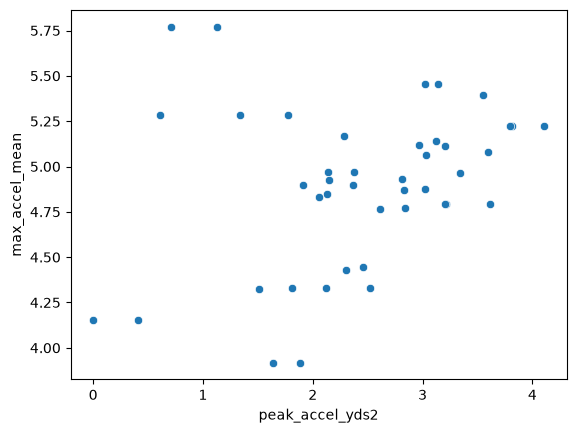

In [100]:
sns.scatterplot(data=shuttle_3cone_df, x="peak_accel_yds2", y="max_accel_mean")
# shuttle_3cone_df

In [105]:
shuttle_3cone_df.drop(columns=['event_id', 'attempt', 'n_dec_bouts', 'n_acc_bouts']).corr()

,max_braking_mag,mean_braking_mag,min_braking_dist_per_yds,max_accel_mean,max_speed_in_bout,peak_accel_yds2
max_braking_mag,1.000000,0.820273,0.400261,0.603665,0.487319,0.271023
mean_braking_mag,0.820273,1.000000,0.706927,0.614929,0.462204,0.292411
min_braking_dist_per_yds,0.400261,0.706927,1.000000,0.376070,0.349450,0.234538
max_accel_mean,0.603665,0.614929,0.376070,1.000000,0.764872,0.267247
max_speed_in_bout,0.487319,0.462204,0.349450,0.764872,1.000000,0.174502
peak_accel_yds2,0.271023,0.292411,0.234538,0.267247,0.174502,1.000000
